In [1]:
import os
import sys
import importlib
import matplotlib.pyplot as plt
import tensorflow as tf

project_root = os.path.abspath("..")
preprocessing_dir = os.path.join(
    project_root,
    "preprocessing"
)

if preprocessing_dir not in sys.path:
    sys.path.insert(0, preprocessing_dir)

import data_augmentation

importlib.reload(data_augmentation)

print("Data augmentation module loaded successfully!")

Data augmentation module loaded successfully!


In [2]:
augmentation_pipeline = (
    data_augmentation.create_augmentation_pipeline()
)

augmentation_pipeline

<Sequential name=dr_data_augmentation, built=False>

In [3]:
image_path = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train_images\\0d9a9896f801.png"

In [4]:
from image_preprocessing import load_image

image = load_image(image_path)

print("Original shape:", image.shape)

Original shape: (1050, 1050, 3)


In [ ]:
image_tensor = tf.convert_to_tensor(
    image,
    dtype=tf.float32
)

image_tensor = tf.expand_dims(
    image_tensor,
    axis=0
)

print(image_tensor.shape)

(1, 1050, 1050, 3)


In [6]:
augmented_images = []

for _ in range(5):

    augmented = augmentation_pipeline(
        image_tensor,
        training=True
    )

    augmented_images.append(
        augmented[0].numpy()
    )

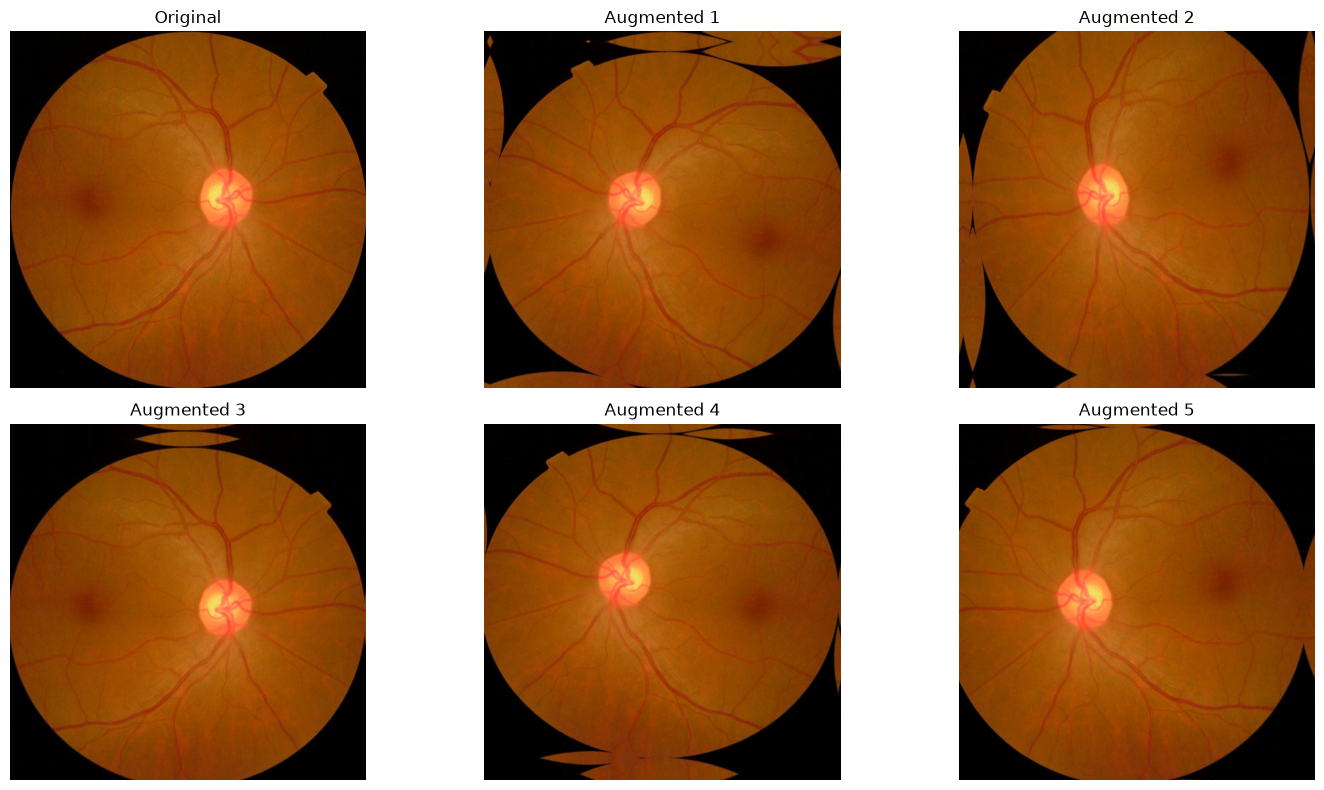

In [7]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

for i in range(5):

    plt.subplot(2, 3, i + 2)

    plt.imshow(
        augmented_images[i].astype("uint8")
    )

    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()